# Criiq — Data Shape, Sources & Insights

This notebook gives a tour of the data collected for **Criiq** (multi-format cricket
selection intelligence — scope: **T20I**, women's primary + men's). It covers:

1. **Where the data comes from** and **how it was collected**
2. The **shape** of the database (tables, row counts, coverage)
3. A set of **insights** drawn straight from the ball-by-ball data
4. An **honest note** on what is *not* in the data and why

> Everything here reads from a single SQLite database produced by the pipeline:
> `data/criiq.db`. If it's missing, run `python -m criiq_data.cli refresh` first.

## 1. Data sources & how they were collected

| # | Source | What it provides | How it's collected | Access / licence |
|---|--------|------------------|--------------------|------------------|
| 1 | **Cricsheet** (`cricsheet.org/downloads`) | **Ball-by-ball** CSVs for every international T20I — every delivery, lineups, results, venues | Bulk ZIP download (`t20s_female_csv2.zip`, `t20s_male_csv2.zip`), parsed into SQLite. Incremental: re-downloaded only when changed | Open / free for research |
| 2 | **Cricsheet people register** (`cricsheet.org/register/people.csv`) | The **matching key**: every player's stable Cricsheet id **plus `key_cricinfo`** (their ESPNcricinfo id) | Downloaded as CSV, loaded into the `people` table | Open / free |
| 3 | **ESPNcricinfo** | *Intended:* career aggregates, bowling style, batting hand | **Blocked** — verified HTTP 403 on every endpoint. Not used as a live source | Scraping disallowed |
| 4 | **Wikidata** (`query.wikidata.org`) | **Nationality** + partial **playing role** (linked via the ESPNcricinfo-id property P2697) | SPARQL query batched over our player ids | Open / free (CC0) |
| 5 | **ICC / board RSS feeds** | Retirement news | `feedparser` scans headlines for retirement keywords → stored as *PENDING* alerts for human confirmation (never auto-applied) | Public feeds |
| 6 | **Manual styles CSV** (`data/styles/player_styles.csv`) | **Bowling style** + **batting hand** (for pace/spin & LHB/RHB splits) | Filled by hand for the active pool, merged into the DB | Curated |

**The match between sources is deterministic, not fuzzy:** Cricsheet's register
carries `key_cricinfo`, so each player links straight to their ESPNcricinfo id.
Chain: `delivery name → match info registry → Cricsheet id → key_cricinfo → ESPNcricinfo`.

**Collection pipeline (one command: `python -m criiq_data.cli refresh`):**

```
download (Cricsheet zips + register)
   → ingest (parse + validate → SQLite)
   → identity (match Cricsheet ↔ ESPNcricinfo id; derive role; normalise venues)
   → styles (Wikidata seed + manual CSV)
   → registry (eligibility: retirement/recall flags)
   → player cards (latest score, form, impact, H2H)
   → advanced profiles (phase strengths, archetype, bowling usage, splits)
```

## 2. Connect to the database

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath("."))          # so `criiq_data` imports work
import pandas as pd
import matplotlib.pyplot as plt
from criiq_data.db import connect

conn = connect("data/criiq.db")                   # sqlite3 connection (Row factory)
def q(sql, params=()):
    return pd.read_sql_query(sql, conn, params=params)

print("Connected to:", os.path.abspath("data/criiq.db"))

Connected to: D:\College\6. Sem\Minor Project\criiq\data-collection\data\criiq.db


### Database shape — tables, rows, columns

In [2]:
tables = ["matches","deliveries","players","player_registry","player_cards",
          "player_advanced","player_styles","identifier_map","people","venues",
          "retirement_alerts"]
rows = []
for t in tables:
    n = conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    cols = len(conn.execute(f"PRAGMA table_info({t})").fetchall())
    rows.append({"table": t, "rows": n, "columns": cols})
pd.DataFrame(rows)

,table,rows,columns
0,matches,5428,18
1,deliveries,1226642,17
2,players,7227,13
3,player_registry,7227,20
4,player_cards,7043,11
5,player_advanced,6982,5
6,player_styles,2799,6
7,identifier_map,8158,2
8,people,18140,5
9,venues,448,3


### What's in each table (quick reference)

- **matches / deliveries** — every match and every ball (the raw spine from Cricsheet)
- **people / identifier_map** — the register and name→id links used for matching
- **players** — one canonical row per player (with `key_cricinfo`, role, etc.)
- **player_registry** — eligibility per player/format (retirement, recall flag, last appearance)
- **player_cards** — dashboard-ready: latest score, form/RFI, team impact, H2H
- **player_advanced** — strengths: phase splits, archetype, bowling usage, vs-pace/spin
- **player_styles** — bowling style / batting hand provenance
- **venues** — venue name normalisation

### Coverage by gender & date range

In [3]:
q('''SELECT gender, COUNT(*) AS matches, MIN(date) AS first_match, MAX(date) AS last_match
     FROM matches GROUP BY gender''')

,gender,matches,first_match,last_match
0,female,2035,2009-06-18,2026-06-15
1,male,3393,2005-02-17,2026-06-14


### Matches ingested per year

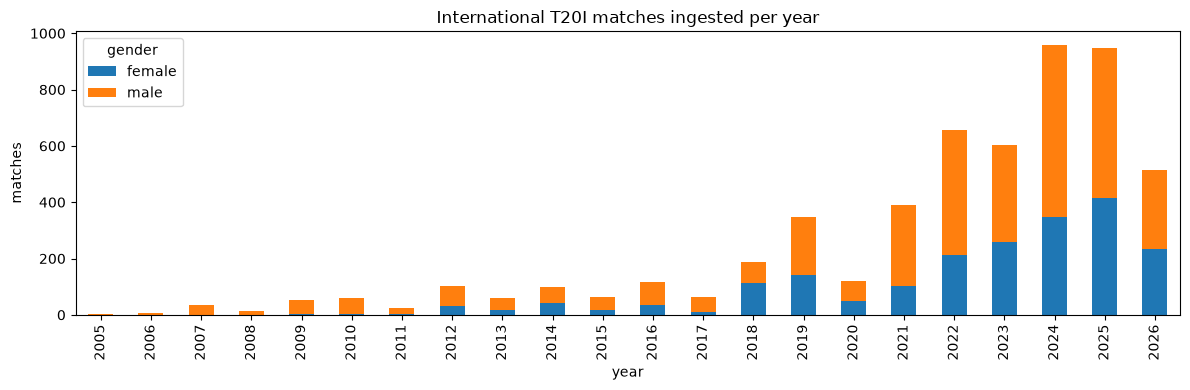

In [4]:
mpy = q('''SELECT CAST(substr(date,1,4) AS INTEGER) AS year, gender, COUNT(*) AS n
           FROM matches WHERE date IS NOT NULL GROUP BY year, gender''')
pivot = mpy.pivot(index="year", columns="gender", values="n").fillna(0)
ax = pivot.plot(kind="bar", stacked=True, figsize=(12,4),
                title="International T20I matches ingested per year")
ax.set_xlabel("year"); ax.set_ylabel("matches"); plt.tight_layout(); plt.show()

### A peek at the raw ball-by-ball data (5 deliveries)

In [5]:
print("deliveries:", conn.execute("SELECT COUNT(*) FROM deliveries").fetchone()[0], "rows")
q("SELECT match_id, innings, over, ball_in_over, striker, bowler, runs_off_bat, "
  "wicket_type, player_dismissed FROM deliveries LIMIT 5")

deliveries: 1226642 rows


,match_id,innings,over,ball_in_over,striker,bowler,runs_off_bat,wicket_type,player_dismissed
0,1043989,1,0,1,MM Lanning,LMM Tahuhu,1,None,None
1,1043989,1,0,2,BL Mooney,LMM Tahuhu,0,None,None
2,1043989,1,0,3,BL Mooney,LMM Tahuhu,0,None,None
3,1043989,1,0,4,BL Mooney,LMM Tahuhu,1,None,None
4,1043989,1,0,5,MM Lanning,LMM Tahuhu,0,None,None


## 3. Identity / matching — how well do the sources line up?

The whole system depends on linking each Cricsheet player to their ESPNcricinfo id.

In [6]:
total  = conn.execute("SELECT COUNT(*) FROM players").fetchone()[0]
withk  = conn.execute("SELECT COUNT(*) FROM players WHERE key_cricinfo IS NOT NULL AND key_cricinfo!=''").fetchone()[0]
review = conn.execute("SELECT COUNT(*) FROM players WHERE needs_review=1").fetchone()[0]
print(f"players (actual playing XIs): {total}")
print(f"matched to ESPNcricinfo id : {withk}  ({100*withk/total:.1f}%)")
print(f"need manual review (no key): {review}")
q("SELECT resolution_method, COUNT(*) AS n FROM players GROUP BY resolution_method ORDER BY n DESC")

players (actual playing XIs): 7227
matched to ESPNcricinfo id : 7226  (100.0%)
need manual review (no key): 1


,resolution_method,n
0,register,7226
1,register_no_cricinfo,1


### Style/metadata coverage (what still needs filling)

In [7]:
from criiq_data import styles
cov = styles.coverage(conn)
print(json.dumps(cov, indent=2))
print("\\nNote: bowling_style / batting_hand come from the manual CSV; "
      "until filled, vs-pace/spin and vs-LHB/RHB splits stay empty (never guessed).")

{
  "players": 7227,
  "with_bowling_style": 0,
  "with_batting_hand": 0,
  "with_role": 42
}
\nNote: bowling_style / batting_hand come from the manual CSV; until filled, vs-pace/spin and vs-LHB/RHB splits stay empty (never guessed).


## 4. The player universe

Roles are *derived* from the ball-by-ball (who bats / who bowls). Archetypes come
from the advanced profile (entry phase, strike-rate progression, death-overs share).

,derived_role,n
0,batter,3534
1,all-rounder,1786
2,bowler,1400
3,unknown,507


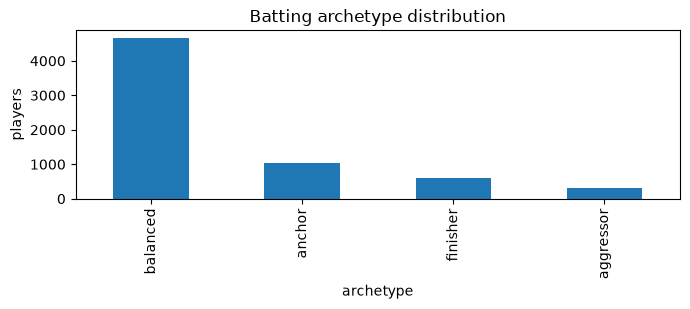

,archetype,n
0,balanced,4653
1,anchor,1024
2,finisher,594
3,aggressor,318


In [8]:
display(q("SELECT derived_role, COUNT(*) AS n FROM players GROUP BY derived_role ORDER BY n DESC"))
arch = q("SELECT archetype, COUNT(*) AS n FROM player_advanced WHERE archetype IS NOT NULL "
         "GROUP BY archetype ORDER BY n DESC")
ax = arch.set_index("archetype")["n"].plot(kind="bar", figsize=(7,3.2),
        title="Batting archetype distribution")
ax.set_ylabel("players"); plt.tight_layout(); plt.show()
arch

## 5. Batting insights

### Run rate & boundary % by phase (powerplay / middle / death)
A classic signal: scoring accelerates through the innings.

,gender,phase,run_rate,boundary_pct
0,female,1_powerplay,5.51,10.6
1,female,2_middle,5.71,8.2
2,female,3_death,6.74,10.0
3,male,1_powerplay,7.36,16.9
4,male,2_middle,7.14,11.6
5,male,3_death,8.79,16.1


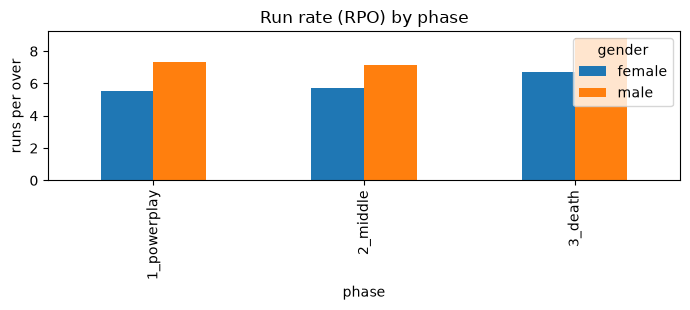

In [9]:
phase = q('''
SELECT m.gender,
  CASE WHEN d.over<=5 THEN '1_powerplay' WHEN d.over<=14 THEN '2_middle' ELSE '3_death' END AS phase,
  ROUND(6.0*SUM(d.runs_total)/SUM(CASE WHEN d.wides=0 AND d.noballs=0 THEN 1 ELSE 0 END),2) AS run_rate,
  ROUND(100.0*SUM(CASE WHEN d.runs_off_bat IN (4,6) THEN 1 ELSE 0 END)
        /SUM(CASE WHEN d.wides=0 THEN 1 ELSE 0 END),1) AS boundary_pct
FROM deliveries d JOIN matches m ON d.match_id=m.match_id
GROUP BY m.gender, phase ORDER BY m.gender, phase
''')
display(phase)
pv = phase.pivot(index="phase", columns="gender", values="run_rate")
ax = pv.plot(kind="bar", figsize=(7,3.2), title="Run rate (RPO) by phase")
ax.set_ylabel("runs per over"); plt.tight_layout(); plt.show()

### Top run-scorers — women's **and** men's T20I (min 500 balls faced)

In [10]:
def top_batters(gender, n=12):
    return q('''
    SELECT d.striker AS player, SUM(d.runs_off_bat) AS runs,
           SUM(CASE WHEN d.wides=0 THEN 1 ELSE 0 END) AS balls,
           ROUND(100.0*SUM(d.runs_off_bat)/SUM(CASE WHEN d.wides=0 THEN 1 ELSE 0 END),1) AS strike_rate
    FROM deliveries d JOIN matches m ON d.match_id=m.match_id
    WHERE m.gender=?
    GROUP BY d.striker
    HAVING SUM(CASE WHEN d.wides=0 THEN 1 ELSE 0 END) >= 500
    ORDER BY runs DESC LIMIT ''' + str(int(n)), (gender,))

print("WOMEN'S T20I — top run-scorers"); display(top_batters("female"))
print("MEN'S T20I — top run-scorers");   display(top_batters("male"))

WOMEN'S T20I — top run-scorers


,player,runs,balls,strike_rate
0,S Mandhana,4103,3229,127.1
1,BL Mooney,3508,2782,126.1
2,AC Jayangani,3282,2840,115.6
3,DN Wyatt,3269,2464,132.7
4,H Kaur,3235,2818,114.8
5,SW Bates,3169,2895,109.5
6,HK Matthews,3094,2623,118.0
7,ER Oza,3083,2564,120.2
8,GH Lewis,2983,2529,118.0
9,SFM Devine,2947,2356,125.1


MEN'S T20I — top run-scorers


,player,runs,balls,strike_rate
0,Babar Azam,4545,3542,128.3
1,RG Sharma,4042,2874,140.6
2,JC Buttler,3999,2699,148.2
3,V Kohli,3969,2917,136.1
4,MJ Guptill,3517,2587,135.9
5,Mohammad Rizwan,3386,2687,126.0
6,DA Warner,3254,2279,142.8
7,SA Yadav,3220,1980,162.6
8,PR Stirling,3160,2360,133.9
9,AJ Finch,3120,2189,142.5


## 6. Bowling insights

### Top wicket-takers — women's **and** men's T20I (min 300 legal balls)

In [11]:
def top_bowlers(gender, n=12):
    return q('''
    SELECT d.bowler AS player,
      SUM(CASE WHEN d.wicket_type IN ('bowled','caught','lbw','stumped','caught and bowled','hit wicket')
                AND d.player_dismissed IS NOT NULL THEN 1 ELSE 0 END) AS wickets,
      ROUND(6.0*SUM(d.runs_off_bat+d.wides+d.noballs)
            /SUM(CASE WHEN d.wides=0 AND d.noballs=0 THEN 1 ELSE 0 END),2) AS economy
    FROM deliveries d JOIN matches m ON d.match_id=m.match_id
    WHERE m.gender=?
    GROUP BY d.bowler
    HAVING SUM(CASE WHEN d.wides=0 AND d.noballs=0 THEN 1 ELSE 0 END) >= 300
    ORDER BY wickets DESC LIMIT ''' + str(int(n)), (gender,))

print("WOMEN'S T20I — top wicket-takers"); display(top_bowlers("female"))
print("MEN'S T20I — top wicket-takers");   display(top_bowlers("male"))

WOMEN'S T20I — top wicket-takers


,player,wickets,economy
0,DB Sharma,162,6.33
1,T Putthawong,149,4.15
2,S Ecclestone,146,6.06
3,ML Schutt,142,6.42
4,KY Chan,124,4.44
5,O Kamchomphu,122,4.61
6,Vaishnave Mahesh,117,4.75
7,Nida Dar,111,5.97
8,HK Matthews,110,6.34
9,H Ishimwe,108,4.54


MEN'S T20I — top wicket-takers


,player,wickets,economy
0,IS Sodhi,164,8.17
1,TG Southee,164,8.12
2,AU Rashid,161,7.49
3,PWH de Silva,153,7.18
4,Mustafizur Rahman,148,7.27
5,Ehsan Khan,144,6.16
6,A Zampa,143,7.40
7,MJ Santner,142,7.17
8,S Lamichhane,135,6.20
9,Rizwan Butt,133,6.85


## 7. Career stats — batting **and** bowling (both genders)

Full careers per player live in the `player_career` table: batting average /
strike rate / HS / 50s / 100s **and** bowling deliveries / wickets / economy /
average / strike rate / best figures. All-rounders therefore carry both sides.

In [12]:
career_df = pd.read_sql_query("SELECT * FROM player_career WHERE format='T20'", conn)

# gender per player (a player plays one programme) for even-handed splits
gmap = pd.read_sql_query('''
  SELECT p.player_id, m.gender, COUNT(*) c
  FROM players p JOIN identifier_map im ON im.identifier=p.cricsheet_identifier
  JOIN match_players mp ON mp.player_name=im.player_name
  JOIN matches m ON m.match_id=mp.match_id
  GROUP BY p.player_id, m.gender''', conn)
gmap = gmap.sort_values("c").drop_duplicates("player_id", keep="last")[["player_id", "gender"]]
career_df = career_df.merge(gmap, on="player_id", how="left")

def bat_career(gender, n=10):
    d = career_df[(career_df.gender == gender) & (career_df.balls_faced >= 500)]
    return d.sort_values("runs", ascending=False).head(n)[
        ["name", "role", "bat_innings", "runs", "bat_average", "bat_strike_rate",
         "high_score", "fifties", "hundreds"]]

def bowl_career(gender, n=10):
    d = career_df[(career_df.gender == gender) & (career_df.balls_bowled >= 300)]
    return d.sort_values("wickets", ascending=False).head(n)[
        ["name", "role", "bowl_innings", "wickets", "economy", "bowl_average",
         "bowl_strike_rate", "best_bowling"]]

print("WOMEN'S T20I — batting careers"); display(bat_career("female"))
print("MEN'S T20I — batting careers");   display(bat_career("male"))
print("WOMEN'S T20I — bowling careers"); display(bowl_career("female"))
print("MEN'S T20I — bowling careers");   display(bowl_career("male"))

WOMEN'S T20I — batting careers


,name,role,bat_innings,runs,bat_average,bat_strike_rate,high_score,fifties,hundreds
2570,S Mandhana,batter,144,4103,31.6,127.1,112,33,1
2257,BL Mooney,batter,111,3508,41.3,126.1,117,28,2
4705,AC Jayangani,all-rounder,123,3282,28.3,115.6,119,14,3
4395,DN Wyatt,all-rounder,139,3269,25.5,132.7,124,21,3
2292,H Kaur,all-rounder,135,3235,30.8,114.8,103,14,1
3767,SW Bates,all-rounder,115,3169,30.2,109.5,124,18,1
5771,HK Matthews,all-rounder,110,3094,31.3,118.0,132,21,3
6973,ER Oza,all-rounder,105,3083,34.6,120.2,158,12,5
698,GH Lewis,all-rounder,108,2983,31.7,118.0,119,18,2
6066,SFM Devine,all-rounder,109,2947,31.4,125.1,105,22,1


MEN'S T20I — batting careers


,name,role,bat_innings,runs,bat_average,bat_strike_rate,high_score,fifties,hundreds
3790,Babar Azam,batter,134,4545,39.2,128.3,122,38,3
3179,RG Sharma,all-rounder,144,4042,30.9,140.6,118,31,4
4199,JC Buttler,batter,139,3999,34.2,148.2,101,28,1
5092,V Kohli,all-rounder,112,3969,48.4,136.1,94,37,0
1142,MJ Guptill,batter,117,3517,32.0,135.9,105,20,2
1249,Mohammad Rizwan,batter,91,3386,47.7,126.0,104,30,1
6025,DA Warner,batter,108,3254,33.9,142.8,100,28,1
1025,SA Yadav,batter,105,3220,36.6,162.6,117,24,4
5659,PR Stirling,all-rounder,130,3160,26.3,133.9,115,20,1
5044,AJ Finch,batter,103,3120,34.3,142.5,172,19,2


WOMEN'S T20I — bowling careers


,name,role,bowl_innings,wickets,economy,bowl_average,bowl_strike_rate,best_bowling
827,DB Sharma,all-rounder,138.0,162.0,6.33,19.4,18.4,5/10
929,T Putthawong,all-rounder,92.0,149.0,4.15,9.2,13.3,5/3
5613,S Ecclestone,all-rounder,106.0,146.0,6.06,16.5,16.3,4/18
590,ML Schutt,bowler,116.0,142.0,6.42,17.9,16.7,5/15
2734,KY Chan,all-rounder,85.0,124.0,4.44,10.3,14.0,5/4
2219,O Kamchomphu,all-rounder,105.0,122.0,4.61,12.6,16.4,5/18
1323,Vaishnave Mahesh,all-rounder,90.0,117.0,4.75,11.2,14.1,4/10
6496,Nida Dar,all-rounder,122.0,111.0,5.97,22.1,22.2,5/21
5771,HK Matthews,all-rounder,104.0,110.0,6.34,19.8,18.8,4/10
7028,H Ishimwe,all-rounder,79.0,108.0,4.54,10.8,14.2,5/17


MEN'S T20I — bowling careers


,name,role,bowl_innings,wickets,economy,bowl_average,bowl_strike_rate,best_bowling
514,TG Southee,all-rounder,122.0,164.0,8.12,22.8,16.8,5/18
2755,IS Sodhi,all-rounder,134.0,164.0,8.17,23.1,17.0,4/12
951,AU Rashid,all-rounder,136.0,161.0,7.49,23.2,18.6,4/2
4625,PWH de Silva,all-rounder,89.0,153.0,7.18,15.8,13.2,4/9
291,Mustafizur Rahman,all-rounder,114.0,148.0,7.27,20.4,16.9,6/10
5781,Ehsan Khan,all-rounder,100.0,144.0,6.16,15.6,15.2,4/5
541,A Zampa,all-rounder,110.0,143.0,7.40,20.9,16.9,5/19
6251,MJ Santner,all-rounder,130.0,142.0,7.17,23.3,19.5,4/11
4909,S Lamichhane,all-rounder,75.0,135.0,6.20,13.0,12.6,5/9
6326,Rizwan Butt,all-rounder,89.0,133.0,6.85,16.5,14.4,6/9


### All-rounders carry both batting and bowling (this was the gap)

Anyone with both batting and bowling volume shows a full two-sided career —
runs **and** deliveries/wickets/economy together.

In [13]:
def allrounders(gender, n=10):
    d = career_df[(career_df.gender == gender) &
                  (career_df.balls_faced >= 300) & (career_df.balls_bowled >= 300)]
    return d.sort_values("wickets", ascending=False).head(n)[
        ["name", "runs", "bat_strike_rate", "wickets", "economy", "bowl_strike_rate",
         "best_bowling"]]

print("WOMEN'S T20I — top all-rounders (both disciplines)"); display(allrounders("female"))
print("MEN'S T20I — top all-rounders (both disciplines)");   display(allrounders("male"))

WOMEN'S T20I — top all-rounders (both disciplines)


,name,runs,bat_strike_rate,wickets,economy,bowl_strike_rate,best_bowling
827,DB Sharma,1198,106.2,162.0,6.33,18.4,5/10
2734,KY Chan,1278,95.2,124.0,4.44,14.0,5/4
6496,Nida Dar,1796,103.0,111.0,5.97,22.2,5/21
5771,HK Matthews,3094,118.0,110.0,6.34,18.8,4/10
7028,H Ishimwe,901,100.2,108.0,4.54,14.2,5/17
3253,AC Kerr,1930,118.6,106.0,6.14,20.1,4/20
1946,IJR Zwilling,881,93.6,95.0,5.18,19.1,3/6
6973,ER Oza,3083,120.2,95.0,4.96,15.9,3/0
4661,J Mbabazi,1098,76.4,91.0,4.80,16.0,4/12
2429,N Boochatham,900,78.9,89.0,4.47,17.7,4/3


MEN'S T20I — top all-rounders (both disciplines)


,name,runs,bat_strike_rate,wickets,economy,bowl_strike_rate,best_bowling
4625,PWH de Silva,711,120.7,153.0,7.18,13.2,4/9
5781,Ehsan Khan,373,108.4,144.0,6.16,15.2,4/5
6251,MJ Santner,1087,130.6,142.0,7.17,19.5,4/11
3443,Shakib Al Hasan,2295,122.5,131.0,6.92,18.2,5/20
6934,MR Adair,814,129.6,128.0,7.78,15.4,4/13
4310,Shadab Khan,904,146.8,118.0,7.50,19.6,4/8
2510,Shahid Afridi (2),1637,157.0,114.0,6.84,20.1,4/11
5996,HH Pandya,2221,145.1,114.0,8.33,19.3,4/16
352,Shahid Afridi,1637,157.0,114.0,6.84,20.1,4/11
1754,Virandeep Singh,3034,125.9,111.0,5.41,15.4,4/5


## 8. Eligibility, retirement & age (the registry)

Status is inferred from activity: **ACTIVE** (in an ICC ranking, or appeared
within ~18 months), **INACTIVE** (no appearance for 3+ years — likely
retired/dropped), else **UNKNOWN**. Players absent > 180 days get a recall flag.
Age advisory and career phase are role-specific (a 38-y/o quick vs a 40-y/o
spinner). ICC rank, when supplied via `data/rankings/icc_rankings.csv`, both fills
the rank and confirms the player is active (retired players drop off ICC lists).

In [14]:
reg = q("SELECT COUNT(*) AS total, SUM(recall_flag) AS recalled FROM player_registry")
t, r = int(reg.total[0]), int(reg.recalled[0])
print(f"registry rows: {t}  |  recall-flagged (>180 days): {r} ({100*r/t:.1f}%)")
print("\nretirement / activity status:")
display(q("SELECT retirement_status, COUNT(*) AS n FROM player_registry GROUP BY retirement_status ORDER BY n DESC"))
print("career phase (where DOB known):")
display(q("SELECT career_phase, COUNT(*) AS n FROM player_registry WHERE career_phase IS NOT NULL GROUP BY career_phase ORDER BY n DESC"))
print("age-advisory flagged:", int(q("SELECT COUNT(*) AS n FROM player_registry WHERE age_advisory=1").n[0]))

registry rows: 7227  |  recall-flagged (>180 days): 5105 (70.6%)

retirement / activity status:


,retirement_status,n
0,ACTIVE,3599
1,INACTIVE,2295
2,UNKNOWN,1333


career phase (where DOB known):


,career_phase,n
0,PEAK,1646
1,EXPERIENCED,535
2,EMERGING,335
3,DECLINING,255


age-advisory flagged: 86


In [15]:
# retirement reflected: long-absent stars are flagged INACTIVE
q('''SELECT p.canonical_name AS player, pr.retirement_status, pr.days_since_last_appearance AS days_out,
        pr.age_at_last_match AS age, pr.career_phase, pr.icc_rank
     FROM player_registry pr JOIN players p ON p.player_id=pr.player_id
     WHERE pr.format='T20' AND p.canonical_name IN
       ('MM Lanning','SR Tendulkar','SW Bates','SFM Devine','EA Perry')''')

,player,retirement_status,days_out,age,career_phase,icc_rank
0,MM Lanning,INACTIVE,1205,30.9,PEAK,None
1,SW Bates,ACTIVE,21,38.7,DECLINING,None
2,SFM Devine,ACTIVE,2,36.8,DECLINING,None
3,EA Perry,ACTIVE,2,35.6,EXPERIENCED,None
4,SR Tendulkar,INACTIVE,7136,33.6,EXPERIENCED,None


## 9. Match impact & the individual performance sheet (for selectors)

Beyond runs and wickets: **how much each player swings matches** — contribution
share, partnership-breaking, top-order scalps, win contribution, Player-of-the-
Match, situational (setting vs chasing) batting, and a transparent importance
score. The `sheet` command curates all of it per player.

In [16]:
imp = pd.read_sql_query("SELECT * FROM player_impact WHERE format='T20'", conn)
names = pd.read_sql_query("SELECT player_id, canonical_name FROM players", conn)
imp = imp.merge(names, on="player_id").merge(gmap, on="player_id", how="left")

def top_importance(gender, n=10):
    d = imp[(imp.gender == gender) & (imp.matches >= 20)]
    return d.sort_values("importance_score", ascending=False).head(n)[
        ["canonical_name", "matches", "importance_score", "win_pct",
         "player_of_match", "bat_contribution_pct", "bowl_contribution_pct",
         "top_order_scalps"]]

print("WOMEN'S T20I — highest-impact players"); display(top_importance("female"))
print("MEN'S T20I — highest-impact players");   display(top_importance("male"))

WOMEN'S T20I — highest-impact players


,canonical_name,matches,importance_score,win_pct,player_of_match,bat_contribution_pct,bowl_contribution_pct,top_order_scalps
6261,J Gunasekar,28,90.2,82.1,12,29.4,11.6,9
6603,KE Bryce,60,89.6,58.3,15,24.4,20.8,51
6973,ER Oza,106,89.2,67.0,24,26.5,16.7,44
3860,K Arua,22,88.6,68.2,3,13.0,22.0,12
1230,Q Abel,43,88.4,53.5,10,23.5,20.6,27
2734,KY Chan,85,87.9,55.3,10,16.3,22.1,65
5283,MD Bimenyimana,79,86.7,63.3,15,18.6,16.3,38
5771,HK Matthews,110,85.7,42.7,22,22.6,18.5,71
6602,CM Gough,40,85.6,57.5,8,26.6,14.6,15
5818,JE Ronalds,36,85.1,61.1,9,17.6,20.2,13


MEN'S T20I — highest-impact players


,canonical_name,matches,importance_score,win_pct,player_of_match,bat_contribution_pct,bowl_contribution_pct,top_order_scalps
1302,AR Ramjani,58,92.0,84.5,11,12.7,21.6,54
6159,KS Leverock,25,91.0,64.0,4,19.4,19.8,18
3320,Yasir Ali,36,90.7,80.6,6,15.5,18.4,23
6460,Taranjeet Singh,43,90.1,60.5,9,22.0,17.2,26
3448,Faheem Nazir,22,89.8,59.1,5,24.8,20.1,11
371,HJ Manenti,23,89.2,65.2,3,14.4,22.1,21
2926,Karanbir Singh,48,89.0,70.8,9,28.3,16.1,18
4897,Aqib Ilyas,47,88.3,53.2,7,19.9,19.9,24
4311,B Ward,42,88.2,71.4,7,13.4,20.3,27
1580,J Coetzee,26,88.2,61.5,6,14.0,22.5,22


### Full performance sheet — example (Ash Gardner)

In [17]:
from criiq_data import sheet
row = sheet.find_player(conn, "%Gardner%")
s = sheet.get_sheet(conn, row["player_id"], "T20", top_opponents=8)
print("SELECTOR SUMMARY")
for line in s["selector_summary"]:
    print("  -", line)
print("\nIMPORTANCE COMPONENTS:")
print(json.dumps(s["impact"]["importance_components"], indent=2))
print("\nRECORD VS EACH OPPONENT:")
display(pd.DataFrame(s["record_vs_opponent"])[
    ["opponent", "matches", "won", "runs", "bat_average", "bat_strike_rate",
     "wickets", "economy", "best_bowling", "player_of_match"]])

SELECTOR SUMMARY


  - Australia | all-rounder | age 29.2
  - Importance 77.1/100 - wins 74.7% of matches featured, 11 PotM
  - Batting: 1489 runs @ avg 24.0, SR 126.8 (HS 93, 7x50, 0x100)
  - Bowling: 82 wkts @ econ 6.59, avg 20.9, best 5/12
  - Wicket impact: 41 top-order scalps, avg stand broken 14.0
  - Setting SR 138.9 vs chasing SR 113.8
  - Best batting phase: death (SR 161.9, ranks #19 of 64 in own team)
  - Standout opponent: India (538 runs, 27 wkts in 26 matches)
  - Bogey bowler: DB Sharma (India) - out 4x in 59 balls

IMPORTANCE COMPONENTS:
{
  "contribution_part": 22.9,
  "winning_part": 18.7,
  "standout_part": 23.1,
  "bowling_impact_part": 12.4,
  "inputs": {
    "bat_contribution_pct": 12.5,
    "bowl_contribution_pct": 12.9,
    "win_pct": 74.7,
    "potm_rate": 0.111,
    "top_order_scalps_per_match": 0.414
  }
}

RECORD VS EACH OPPONENT:


,opponent,matches,won,runs,bat_average,bat_strike_rate,wickets,economy,best_bowling,player_of_match
0,India,26,18,538,26.9,135.9,27,7.24,3/16,5
1,New Zealand,19,15,308,22.0,116.2,14,6.88,5/12,4
2,England,16,8,243,20.2,129.3,9,8.04,3/22,1
3,Pakistan,10,8,131,65.5,147.2,10,5.00,4/21,1
4,South Africa,8,6,94,23.5,117.5,6,7.04,2/26,0
5,West Indies,7,6,45,9.0,91.8,7,6.61,3/32,0
6,Bangladesh,5,5,62,31.0,114.8,5,4.54,3/17,0
7,Sri Lanka,4,4,63,21.0,126.0,1,5.75,1/14,0


## 10. Phase ranking, grounds & bogey bowlers

Phase strength **relative to teammates** (where a batter ranks in their own side),
performance **by ground**, and the **bogey bowler** for each batter (who has
dismissed them most). Phase-by-phase vs each opponent is in the performance sheet
(`sheet --name ...`).

In [18]:
ph = pd.read_sql_query('''
  SELECT pp.*, p.canonical_name FROM player_phase pp
  JOIN players p ON p.player_id = pp.player_id
  WHERE pp.format='T20' AND pp.phase='death' AND pp.bat_balls >= 150''', conn)
ph = ph.merge(gmap, on="player_id", how="left")

def best_death(gender, n=8):
    d = ph[ph.gender == gender].sort_values("bat_strike_rate", ascending=False)
    return d.head(n)[["canonical_name", "bat_balls", "bat_strike_rate",
                      "bat_boundary_pct", "bat_team_rank", "bat_team_size"]]

print("WOMEN'S T20I — best death-overs batters (SR, with rank in own team)")
display(best_death("female"))
print("MEN'S T20I — best death-overs batters")
display(best_death("male"))

WOMEN'S T20I — best death-overs batters (SR, with rank in own team)

,canonical_name,bat_balls,bat_strike_rate,bat_boundary_pct,bat_team_rank,bat_team_size
256,GM Harris,186,178.5,26.9,10,64
273,BL Mooney,283,178.4,25.8,11,64
98,N Chantam,241,170.5,23.7,3,33
252,SFM Devine,279,166.3,20.1,13,69
245,RM Ghosh,510,165.9,25.7,17,56
9,O Prendergast,231,165.8,24.2,3,50
92,HC Knight,447,163.8,22.4,18,66
69,L Wolvaardt,255,163.1,23.1,17,62


MEN'S T20I — best death-overs batters


,canonical_name,bat_balls,bat_strike_rate,bat_boundary_pct,bat_team_rank,bat_team_size
59,SA Yadav,274,224.8,36.5,3,56
242,Babar Hayat,200,213.5,30.0,1,38
146,TH David,232,205.2,30.6,2,64
228,DS Airee,468,202.6,27.6,2,37
278,HC Brook,179,201.1,30.7,3,66
141,GJ Maxwell,301,197.0,30.6,4,64
162,Sikandar Raza,353,195.8,27.5,1,54
133,BB McCullum,167,194.6,28.1,4,69


### Performance by ground + bogey bowlers (example: MM Lanning)

In [19]:
from criiq_data import sheet as _sheet, venue_stats, matchups
pid = _sheet.find_player(conn, "%Lanning%")["player_id"]
print("BY GROUND (top venues):")
display(pd.DataFrame(venue_stats.get_by_venue(conn, pid, "T20", limit=8))[
    ["venue_name", "matches", "runs", "bat_average", "bat_strike_rate", "wickets", "economy"]])
print("BOGEY BOWLERS — who has dismissed her most:")
display(pd.DataFrame(matchups.top_dismissers(conn, pid, "T20")["overall"][:8]))

BY GROUND (top venues):


,venue_name,matches,runs,bat_average,bat_strike_rate,wickets,economy
0,County Ground,6,229,57.2,140.5,0,None
1,Melbourne Cricket Ground,5,218,43.6,129.0,0,None
2,North Sydney Oval,5,105,35.0,118.0,0,None
3,Edgbaston,5,91,22.8,121.3,0,None
4,Brabourne Stadium,4,175,NaN,162.0,0,None
5,Kerrydale Oval,4,100,100.0,131.6,0,None
6,Junction Oval,4,96,24.0,129.7,0,None
7,Allan Border Field,4,90,30.0,90.9,0,None


BOGEY BOWLERS — who has dismissed her most:


,bowler_name,bowler_team,dismissals,balls,runs
0,AC Kerr,New Zealand,4,45,49
1,RS Gayakwad,India,4,40,34
2,Nida Dar,Pakistan,3,44,45
3,LMM Tahuhu,New Zealand,2,80,71
4,S Ecclestone,England,2,68,76
5,A Shrubsole,England,2,57,84
6,RP Yadav,India,2,33,31
7,DB Sharma,India,2,25,24


## 11. Example deep-dives — one woman, one man

The card and advanced profile are pre-computed per player, ready to serve. We show
one from each programme so the comparison is even-handed.

In [20]:
from criiq_data import player_card, advanced

def find_player(like):
    # pick the most-capped player matching the name (so "Kohli" -> V Kohli, not A Kohli)
    return conn.execute(
        "SELECT p.player_id, p.canonical_name, COUNT(DISTINCT mp.match_id) AS m "
        "FROM players p JOIN identifier_map im ON im.identifier=p.cricsheet_identifier "
        "JOIN match_players mp ON mp.player_name=im.player_name "
        "WHERE p.canonical_name LIKE ? GROUP BY p.player_id ORDER BY m DESC LIMIT 1",
        (like,)).fetchone()

def deep_dive(like):
    row = find_player(like)
    if not row:
        print("not found:", like); return
    pid, name = row["player_id"], row["canonical_name"]
    print("="*64); print(f"  {name}"); print("="*64)
    print("--- PLAYER CARD ---")
    print(json.dumps(player_card.get_card(conn, pid, "T20"), indent=2))
    print("\n--- ADVANCED PROFILE ---")
    print(json.dumps(advanced.get_advanced(conn, pid, "T20"), indent=2))

### Women's example — Meg Lanning

In [21]:
deep_dive("%Lanning%")

  MM Lanning
--- PLAYER CARD ---
{
  "identity": {
    "player_id": "78225154-1f35-5b7a-a5a4-b8cf729e1b9a",
    "name": "MM Lanning",
    "role": "batter",
    "nationality": "Australia",
    "age": 30.9
  },
  "career": {
    "batting": {
      "innings": 89,
      "runs": 2538,
      "balls": 2206,
      "average": 39.7,
      "strike_rate": 115.0,
      "high_score": 133,
      "fifties": 12,
      "hundreds": 1
    },
    "bowling": {
      "innings": 1,
      "balls": 12,
      "overs": "2.0",
      "runs_conceded": 11,
      "wickets": 1,
      "economy": 5.5,
      "average": 11.0,
      "strike_rate": 12.0,
      "best_bowling": "1/11"
    }
  },
  "latest_match": {
    "date": "2023-02-26",
    "opponent": "South Africa",
    "venue_id": "newlands",
    "result": "won",
    "batting": {
      "runs": 10,
      "balls": 11,
      "not_out": false,
      "strike_rate": 90.9
    },
    "match_summary": {
      "event": "ICC Women's T20 World Cup",
      "venue": "Newlands, Cape T

### Men's example — Virat Kohli

In [22]:
deep_dive("%Kohli%")

  V Kohli
--- PLAYER CARD ---
{
  "identity": {
    "player_id": "65e8f412-5552-59f2-af8f-3af85604002b",
    "name": "V Kohli",
    "role": "batter",
    "nationality": "India",
    "age": 35.6
  },
  "career": {
    "batting": {
      "innings": 112,
      "runs": 3969,
      "balls": 2917,
      "average": 48.4,
      "strike_rate": 136.1,
      "high_score": 94,
      "fifties": 37,
      "hundreds": 0
    },
    "bowling": {
      "innings": 13,
      "balls": 152,
      "overs": "25.2",
      "runs_conceded": 204,
      "wickets": 4,
      "economy": 8.05,
      "average": 51.0,
      "strike_rate": 38.0,
      "best_bowling": "1/13"
    }
  },
  "latest_match": {
    "date": "2024-06-29",
    "opponent": "South Africa",
    "venue_id": "kensington-oval",
    "result": "won",
    "batting": {
      "runs": 76,
      "balls": 59,
      "not_out": false,
      "strike_rate": 128.8
    },
    "match_summary": {
      "event": "ICC Men's T20 World Cup",
      "venue": "Kensington Oval

## 12. Prediction-ready datasets (win/loss + in-game)

These are the model-training tables that turn the descriptive data above into a
predictor. Feature engineering only — model training is the next step.

**`match_features`** — one row per match for **win/loss prediction**. Pre-match
features are computed leakage-safe (only matches *before* each game): each team's
recent form, average score/conceded, head-to-head, toss, and who batted first.
Label: did team1 win.

**`ball_state`** (parquet) — one row per delivery for **live win-probability**:
score, wickets, balls remaining, target, runs required, required vs current run
rate, with the outcome label (did the batting team win). This also lets a later
model measure a player's win-probability impact across a game.

**`player_match_impact`** — one row per player per match: their batting/bowling
contribution share that game, with a result label.

In [23]:
mf = pd.read_sql_query("SELECT * FROM match_features WHERE format='T20'", conn)
print("match_features rows:", len(mf))
print("win/loss label balance (team1_won):")
print(mf["label_team1_won"].value_counts(dropna=False).to_string())
print("\nfeature columns:", [c for c in mf.columns if c not in ('match_id','updated_at')])
display(mf[mf.form_matches >= 5].dropna(subset=["label_team1_won"])
        [["team1", "team2", "winpct_diff", "avg_score_diff", "team1_bat_first",
          "h2h_team1_winpct", "label_team1_won"]].tail(6))

match_features rows:

 5428
win/loss label balance (team1_won):
label_team1_won
1.0    2640
0.0    2631
NaN     157

feature columns: ['format', 'gender', 'date', 'venue_id', 'team1', 'team2', 'toss_winner', 'toss_decision', 'bat_first_team', 'toss_winner_is_team1', 'team1_bat_first', 'form_matches', 'team1_form_winpct', 'team2_form_winpct', 'team1_avg_score', 'team2_avg_score', 'team1_avg_conceded', 'team2_avg_conceded', 'h2h_team1_winpct', 'winpct_diff', 'avg_score_diff', 'label_team1_won', 'result_type']


,team1,team2,winpct_diff,avg_score_diff,team1_bat_first,h2h_team1_winpct,label_team1_won
5422,Sri Lanka,West Indies,0.111,-11.278,1,0.441,1.0
5423,Finland,Norway,0.100,-14.200,1,0.286,1.0
5424,Sweden,Austria,0.200,-4.400,1,0.250,1.0
5425,Sri Lanka,West Indies,0.222,-6.800,1,0.457,0.0
5426,Norway,Austria,0.000,-15.100,1,0.500,0.0
5427,Finland,Sweden,0.000,-26.000,1,0.500,0.0


In [24]:
bs = pd.read_parquet("data/features/ball_state_T20.parquet")
print("ball_state rows:", len(bs), "| second-innings (chase) rows:", int((bs.innings == 2).sum()))
print("a chase, sampled every 200 balls:")
display(bs[(bs.innings == 2) & bs.target.notna()].iloc[::200]
        [["over", "score", "wickets", "balls_remaining", "runs_required",
          "req_run_rate", "current_run_rate", "label_batting_team_won"]].head(6))

ball_state rows: 1226642 | second-innings (chase) rows: 563923
a chase, sampled every 200 balls:


,over,score,wickets,balls_remaining,runs_required,req_run_rate,current_run_rate,label_batting_team_won
125,0,1,0,119,168.0,8.471,6.000,1
448,12,92,6,45,82.0,10.933,7.360,1
901,5,26,4,84,144.0,10.286,4.333,0
1225,17,150,5,12,21.0,10.500,8.333,0
1673,17,104,5,17,35.0,12.353,6.058,0
2131,10,104,4,55,92.0,10.036,9.600,0


## 13. What is *not* in the data (and why it isn't faked)

These were requested but have **no free/legal source** for this scope, so they are
deliberately excluded rather than fabricated:

- **Ball speed (km/h)** — proprietary ball-tracking (Hawk-Eye/CricViz); not published
  for women's / associate cricket.
- **Shot-control %, best shot, number of shot variations** — proprietary CricViz
  metrics from manual shot-by-shot coding; not in any free source.
- **Preferred shots / wagon wheels** — needs shot-coded logs; ESPNcricinfo blocks
  scraping (verified 403) and coverage is absent for this scope.
- **Bowling variations (yorker / googly / slower-ball counts)** — Cricsheet does
  **not** record delivery type, so per-variation stats cannot be derived. Phase
  economy/wickets and pace-vs-spin classification are the available proxies.

The phase strengths, control/aggression proxies, acceleration and archetype in
`player_advanced` are the genuine, data-backed equivalents.

---

### Re-run / refresh
```bash
python -m criiq_data.cli refresh     # update everything (incremental, safe to re-run)
python -m criiq_data.cli status      # quick counts
```